The goal of this series of lab sessions is to discover several classical problems in geometric processing, and to learn some tools and concepts that are recurrent when working with geometric data.

This first lab session serves as an introduction on the topic and is decomposed in two main parts.
The first one is an introduction to pytorch for geometric computations and to the various data structures used to model 3D objects.
The second part is dedicated to shape matching, a fundamental task when comparing geometric data together.

# 0 - Setup

## a - Imports

We first install several libraries required in this notebook. We will use `trimesh` to manipulate 3D meshes, `pyvista` for 3D visualization and `pot` to compute optimal transport between point clouds. Finally, we will use `scipy` and `potpourri3d` in the last section of the lab.

In [ ]:
!pip install pyvista
!pip install "pyvista[jupyter]"
!pip install trimesh
!pip install pot
!pip install potpourri3d

In [ ]:
import os

os.environ["PYVISTA_JUPYTER_BACKEND"] = "static"
os.environ["PYVISTA_OFF_SCREEN"] = "true"

import pyvista as pv

pv.set_jupyter_backend("static")
pv.OFF_SCREEN = True

from IPython.display import Image, display

In [ ]:
import numpy as np
import trimesh

import torch

import scipy
import potpourri3d as pp3d

In [ ]:
import PIL.Image

import matplotlib.pyplot as plt

from matplotlib.collections import LineCollection

from mpl_toolkits.mplot3d import Axes3D
from mpl_toolkits.mplot3d.art3d import Poly3DCollection, Line3DCollection

In [ ]:
%matplotlib inline

## b - Visualization functions and helpers

Here are some useful functions to visualize data and matchings:

In [ ]:
def plot_vertices(vertices, color=None):
  """
  Plot the vertices of a 3D mesh.

  vertices: torch.Tensor(float) of size (N, 3)
    The coordinates of the vertices.
  """
  vertices = vertices.cpu().numpy()

  fig = plt.figure(figsize=(6, 6))
  ax = fig.add_subplot(111, projection='3d')

  if color is None:
    color = 'black'

  ax.scatter(vertices[:, 0], vertices[:, 1], vertices[:, 2], s=1, c=color)

  ax.set_aspect('equal')
  plt.show()


def plot_edges(edges_pos):
  """
  Plot the edges of a 3D mesh.

  edges_pos: torch.Tensor(float) of size (P, 2, 3)
  The coordinates of each edge endpoints. More precisely, the coordinates of the p-th edge are edges_pos[p,0,:] and edges_pos[p,1,:].
  """

  fig = plt.figure(figsize=(6, 6))
  ax = fig.add_subplot(111, projection='3d')

  lines = Line3DCollection(edges_pos.cpu().numpy(), alpha=.7, color='black', lw=1)
  ax.add_collection3d(lines)

  ax.set_aspect('equal')
  plt.show()

In [ ]:
def plot_mesh(vertices, faces, color=None, color_type='vertex', uv=None, texture_path=None, show_edges=True, **kwargs):
  """
  Plot  a 3D mesh.

  vertices: torch.Tensor(float) of size (N, 3)
    The coordinates of the vertices.
  faces: torch.Tensor(int) of size (Q, 3)
    The indices of the mesh triangles.
  color: None or torch.Tensor(float) of size (N,) or (Q,)
    If not None, scalars used to color each vertex/face of the mesh.
  """

  if isinstance(vertices,torch.Tensor):
    vertices = vertices.cpu().numpy()
  if isinstance(faces,torch.Tensor):
    faces = faces.cpu().numpy()
  if isinstance(color,torch.Tensor):
    color = color.cpu().numpy()

  faces_pv = np.hstack([np.full((faces.shape[0], 1), 3), faces]).flatten()
  plotter = pv.Plotter(
      off_screen=True,
      notebook=False,
      window_size=(400, 400)
  )
  mesh = pv.PolyData(vertices, faces_pv)

  if uv is not None:
    mesh.active_texture_coordinates = uv.cpu().numpy()
    plotter.add_mesh(mesh, show_edges=show_edges, scalars=color, texture=pv.read_texture(texture_path), **kwargs)
    plotter.camera_position = 'xz'
  else:
    plotter.add_mesh(mesh, show_edges=show_edges, scalars=color, **kwargs)

  plotter.show(
      screenshot="/tmp/visualization.png",
      auto_close=True
  )
  display(Image(filename="/tmp/visualization.png"))


def plot_mesh_transfer(vertices1, faces1, vertices2, faces2, transport=None, matching=None):
  if matching is not None:
    transport = torch.zeros((vertices1.shape[0], vertices2.shape[0]))
    transport[torch.arange(vertices1.shape[0]), matching] = 1 / vertices2.shape[0]

  uv_source = torch.concatenate([vertices2[:,:1], vertices2[:,2:]],dim=1)
  uv_transfered = (transport.T[:,:,None] * uv_source[:, None, :]).sum(axis=0) / transport.T[:,:].sum(axis=0)[:,None]

  plot_mesh(vertices2, faces2, uv=uv_source, texture_path='uvmap_checker.png', show_edges=False)
  plot_mesh(vertices1, faces1, uv=uv_transfered, texture_path='uvmap_checker.png', show_edges=False)

In [ ]:
def plot_pointcloud(points):
  """
  Plots a 2D point cloud.

  points : torch.Tensor(float) of shape (N, 2)
  """
  points = points.cpu().numpy()

  fig = plt.figure(figsize=(6, 6))
  ax = fig.add_subplot(111)

  plt.scatter(points[:,0], points[:, 1], c='black', s=10)

  ax.set_aspect('equal')
  plt.show()


def plot_matching(points1, points2, transport=None, matching=None):
  """
  Plots the transport plan between two point clouds.

  points1 : torch.tensor(float) of shape (N, 2)
  points2 : torch.tensor(float) of shape (M, 2)
  transport : torch.tensor(int) of shape (N, M)
  """
  points1, points2 = points1.cpu().numpy(), points2.cpu().numpy()

  if isinstance(transport, torch.Tensor):
    transport = transport.cpu().numpy()
  if isinstance(matching, torch.Tensor):
    matching = matching.cpu().numpy()

  if transport is not None:
    matching = np.argwhere(transport > (1e-2 * transport.max()))

    orig_idx = matching[:,0]
    target_idx = matching[:,1]

    weights = transport[orig_idx, target_idx]
    weights = weights / np.max(weights)

    alphas = np.maximum(0.5 * weights, 1e-2)
  else:
    orig_idx = np.arange(matching.shape[0])
    target_idx = matching

    alphas = 0.5


  fig = plt.figure(figsize=(6, 6))
  ax = fig.add_subplot(111)

  ax.scatter(points1[:, 0], points1[:, 1], color="green", s=10, alpha=0.5)
  ax.scatter(points2[:, 0], points2[:, 1], color="orange", s=10, alpha=0.5)

  edges = np.transpose([points1[orig_idx], points2[target_idx]], axes=(1, 0, 2))
  lines = LineCollection(edges, alpha=alphas, color='black', lw=1)
  ax.add_collection(lines)

  ax.set_aspect('equal')
  plt.show()


def plot_transfer(points1, points2, transport=None, matching=None):
  """
  Visualizes the color transfer induced by a transport plan between two point clouds.

  points1 : torch.tensor(float) of shape (N, 2)
  points2 : torch.tensor(float) of shape (M, 2)
  transport : torch.tensor(float) of shape (N, M)
  """

  if matching is not None:
    transport = torch.zeros(points1.shape[0], points2.shape[0])
    transport[torch.arange(points1.shape[0]), matching] = 1 / points1.shape[0]

  if isinstance(transport, torch.Tensor):
    transport = transport.cpu().numpy()
  if isinstance(matching, torch.Tensor):
    matching = matching.cpu().numpy()

  points1, points2 = points1.cpu().numpy(), points2.cpu().numpy()

  base_vals = (points2 - points2.min(axis=0, keepdims=True))/ (points2.max(axis=0, keepdims=True) -  points2.min(axis=0, keepdims=True))
  base_color = np.stack([base_vals[:,0], base_vals[:,1], (1 - base_vals[:,0])*(1 - base_vals[:,1])], axis=1)

  transfered_color = (transport.T[:,:,None] * base_color[:, None, :]).sum(axis=0) / transport.T[:,:].sum(axis=0)[:,None]

  fig, axs = plt.subplots(1, 2, figsize=(8, 4))
  axs[0].scatter(points2[:,0], points2[:,1], c=base_color, s=10)
  axs[1].scatter(points1[:,0], points1[:,1], c=transfered_color, s=10)

  axs[0].set_aspect('equal')
  axs[1].set_aspect('equal')

  plt.show()

In [ ]:
def load_image_as_pointcloud(path, N=1000):
  """
  Load an image and sample N points following the distribution defined by its intensity histogram.
  """
  image = torch.load(path)
  rescaled_image = image / image.max()

  points = torch.tensor([])

  while points.shape[0] < N:
    random_points = torch.rand(N, 2) * torch.tensor(image.shape)
    pixel_points = torch.floor(random_points).to(dtype=torch.int)

    accepted = torch.rand(N) < rescaled_image[pixel_points[:,0], pixel_points[:,1]]
    points = random_points[accepted] if points.size == 0 else torch.concatenate([points, random_points[accepted]])

  points = points[:N]

  points = points - torch.mean(points, dim=0)[None, :]
  points = points / torch.mean(torch.linalg.norm(points, dim=1))

  R = torch.tensor([[0, -1], [1, 0]], dtype=torch.float32)
  return torch.einsum('is,st->it',points, R)

# I - Geometric Processing using Pytorch

## a - A short introduction to Pytorch

Pytorch is a scientific computing library that implements several linear algebra routines efficiently. It is very similar to Numpy, with the difference that Pytorch is specifically conceived to implement deep learning methods.
As such, it provides simple ways to design neural networks, but it also provides useful tools in other areas of computer science:

*   Native **GPU parallelization** of linear algebra operations,
*   An **autodifferentiation** framework that allows to compute the gradient of arbitrary functions.

These two items are really valuable in geometric data analysis; therefore, we will mainly use Pytorch in our lab sessions.

The main data structure manipulated in Pytorch is the **tensor**: a generalization of vectors and matrices in arbitrary dimensions. For instance vector is a tensor of dimension $1$; a matrix is a tensor of dimension $2$.

Here are several ways to define tensors. Tensor are strongly typed: to avoid any errors, it is better to specify the data type (dtype)
of the tensor at its creation. The most commonly used dtypes are `torch.float32` (for reals) and
`torch.int64` (for integers), as they are compatible with any GPU.

In [ ]:
"""
Create a vector with user-defined values.
"""
a = torch.tensor([1, 2, 5.5], dtype=torch.float32)
print(f"Shape of a: {a.shape},     \t data type of a: {a.dtype}.")

"""
Create an identity matrix, with integer elements.
"""
b = torch.eye(5 ,5, dtype=torch.int64)
print(f"Shape of b: {b.shape}, \t data type of b: {b.dtype}.")

"""
Create a tensor of zeros with 3 dimensions.
"""
c = torch.zeros((5 ,5, 3), dtype=torch.float32)
print(f"Shape of c: {c.shape}, \t data type of c: {c.dtype}.")

In [ ]:
"""
Create two tensors following a normal distribution centered at 0 with shape (15, 3).
"""
x = torch.normal(mean=torch.zeros((15, 3))) # We must specify the gaussian mean as a tensor which will determine the output shape.
y = torch.normal(mean=torch.zeros((15, 3)))

In [ ]:
"""
If CUDA is available on your machine, the following command directly sends the previous tensors on GPU:
"""
#x = x.to('cuda')
#y = y.to('cuda')

"""
To send the vectors back on CPU, you can use the following syntax:
"""
# x = x.cpu()
# y = y.cpu()

Operations on tensors split in two main categories: pointwise operations and reduction operations.

**Pointwise operations** apply the same computations on each element of the tensor. They output a tensor whose shape is identical to the input one.

In [ ]:
"""
Basic python operations are implemented in pytorch: here, we add 1 to each element of x.
"""
a = x + 1

"""
Other pointwise operations are also available, such as the exponential:
"""
b = torch.exp(x)

"""
Some pointwise operations take two tensors with same shape as inputs.
Here, we take the pointwise sum of elements of x and y.
"""
c = x + y

print(f"Output shapes: {a.shape}, {b.shape}, {c.shape}")

**Reduction operations** aggregate values of the whole tensor or of one of its dimensions. They return a single number, or a new tensor with one dimension less than the input.

In [ ]:
"""
Compute an aggregate value (e.g. sum, mean, or minimum) of all elements in x.
"""
print(f"Sum of x: \t {x.sum()}")
print(f"Average of x: \t {x.mean()}")
print(f"Min. of x: \t {x.min()}")

"""
If we specify a dimension, the aggregation is done on one dimension of x: the corresponding
dimension disappears in the output tensor.
Here, the result is a tensor of shape (15,) that contains the sum of each triplet in the 15 rows of x.
"""
a = x.sum(dim=1)
print(f"Shape of a: {a.shape}")

"""
Here, we compute the mean of each 3 columns of x, yielding a tensor of shape (3,).
"""
b = x.mean(dim=0)
print(f"Shape of b: {b.shape}")

**Index management.** Pytorch also provides simple ways to access specific elements of a tensor using a syntax similar to native python arrays.

In [ ]:
print(x[4])       # Get the 4th row of x
print(x[1:4])     # Get the 1 to 4th rows of x (4th excluded)
print(x[:,0])     # Get the Oth column of x

Integer tensors can also be used to select a subset of tensor elements. Alternatively, using tensor of booleans as indices selects only the tensor elements at positions where the boolean is True.

In [ ]:
"""
Define a tensor of integers.
"""
idx = torch.tensor([1, 2, 5, 9], dtype=torch.int64)

print(x[idx])     # Get the rows of x indexed by the tensor idx
print(x[idx,:2])  # Get the Oth and 1st columns of the rows of x indexed by idx

In [ ]:
"""
Boolean tensor indicating which rows sum to a positive number.
"""
a = x.sum(dim=1) > 0

print(a)
print(x[a])   # Only the rows whose condition is True are selected

Tensor of indices can have arbitrary shapes; in that case, the output shape will be expanded at the indexed dimension to match the shape of the indices tensor.

In [ ]:
idx = torch.tensor([[1, 2, 9, 11], [3, 2, 6, 13]], dtype=torch.int64)

print(f"Shape of idx: {idx.shape}")

a = x[idx]

print(f"Shape of a: {a.shape}")

print(f"a = {a}")

In [ ]:
"""
The computation a=x[idx] is equivalent to:
"""
a = torch.zeros((idx.shape[0], idx.shape[1], x.shape[1]), dtype=torch.float32)

for i in range(idx.shape[0]):
  for j in range(idx.shape[1]):
    for k in range(x.shape[1]):
      a[i,j,k] = x[idx[i,j],k]

print(f"a = {a}")

In [ ]:
"""
Similarly, we can index the other dimension of x:
"""
idx = torch.tensor([[1, 2], [0, 1], [0, 2]], dtype=torch.int64)

print(f"Shape of idx: {idx.shape}")

b = x[:,idx]

print(f"Shape of b: {b.shape}")

print(f"b = {b}")

In [ ]:
"""
The computation b=x[:,idx] is equivalent to:
"""
b = torch.zeros((x.shape[0], idx.shape[0], idx.shape[1]), dtype=torch.float32)
for i in range(x.shape[0]):
  for j in range(idx.shape[0]):
    for k in range(idx.shape[1]):
      b[i,j,k] = x[i, idx[j,k]]

print(f"b = {b}")

**Broadcasting.** In some cases, we want to perform pointwise operations using the same values on each rows or columns. For instance, we may want to add a vector $z$ to each row of $x$ as follows:

$$\text{For all } 0 \leq i < 15 \text{ and } 0 \leq u < 3, \quad  a_{iu} = x_{iu} + z_u.$$

Pytorch implements such operations easily through a mecanism called broadcasting. To do so, we simply need to add empty dimensions to the vector $z$: during the computation, the values of $z$ will be repeated along the empty dimensions.

In [ ]:
"""
Create a tensor of shape (3,).
"""
z = torch.tensor([1., 3., 7.], dtype=torch.float32)

"""
Add an empty dimension to z, so that its shape becomes (1, 3).
"""
z = z[None,:]
# z = z.reshape(1, 3)   # This is equivalent to the previous line

"""When summing x and z together, the vector z is extended in its empty dimension.
As a consequence, z will be added to each row of x, corresponding to the desired operation."""
a = x + z

print(f"a = {a}")

**Linear algebra.** Pytorch efficiently implements linear algebra routines such as matrix-vector or matrix-matrix multiplications. Depending on the situation, there are several ways to compute the same quantities. To illustrate it, we will compute the operation:

$$\text{For all } 0 \leq i < 15 \text{ and } 0 \leq v < 3, \quad y_{iv} = \sum_{u} x_{iu} M_{uv},$$

where $M$ is a $3 \times 3$ matrix.

In [ ]:
"""
Define a 3x3 matrix.
"""
M = torch.normal(mean=torch.zeros(3, 3))

print(f"Shape of M: {M.shape}")

Our quantity of interest corresponds to the matrix-matrix multiplication of $x$ with $M$. The following syntax implements this operation:

In [ ]:
y = x @ M

print(f"y = {y}")

This syntax is compact but it can be tricky, as the management of the tensor dimensions can be confusing. Moreover, it is specific to matrix multiplication and does not generalize to higher-order tensors.

Alternatively, broadcasting provides a more explicit way to implement the desired formula. Indeed, to compute $y_{iv} = \sum_{u} x_{iu} M_{uv}$, we can first compute the pointwise operation:

$$r_{iuv} = x_{iu} M_{uv},$$
then apply the sum reduction over the dimension of $u$:
$$y_{iv} = \sum_u r_{iuv}.$$


In [ ]:
r = x[:,:,None] * M[None,:,:]
y = r.sum(dim=1)

print(f"y = {y}")

Broadcasting is a very polyvalent technique which allows to compute most of the quantities we need in geometric data analysis.
For instance, to compute the following quantity which evaluates, for all $x_i$, the average distance to the point set $y$:

$$ a_{i} = \frac{1}{N} \sum_{j=1}^N \Vert x_i - y_j \Vert =  \frac{1}{N} \sum_{j=1}^N \sqrt{\sum_u (x_{iu} - y_{ju})^2},$$

we can use broadcasting and write:

In [ ]:
k = (x[:,:,None] - y[:,None,:])**2    # k_{iju} = (x_{iu} - y_{ju})^2
d2 = k.sum(dim=2)                     # d2_{ij} = || x_i - y_j ||^2
d = torch.sqrt(d2)                    # d_{ij} = || x_i - y_j ||

a = d.mean(dim=1)                     # a_{ij} = || x_i - y_j ||.mean(dim=1)

print(f"a = {a}")


"""
Alternatively, the function torch.norm directly computes the pairwise norms:
"""
a = torch.norm(x[:,:,None] - y[:,None,:], dim=2).mean(dim=1)

print(f"a = {a}")

The main drawback of broadcasting is its memory cost: all broadcasted tensors are expanded explicitly, taking a lot of space in memory. In a next lab session, we will see how to solve this bottleneck using the Pykeops library.

For operations involving only tensor products and tensor contractions, the function `einsum` provides an optimized way to perform these computations.
It allows to implement broadcasted multiplications followed by sum reduction over one or several dimensions by describing the operation using a single string.
The string specifies the name of each input dimension and each output dimension: for instance, the following quantity

$$ z_{il} = \sum_{jk} a_{ijk} b_{jl} c_j d_{kl} $$

is described by the string `'ijk,jl,j,kl->il'`. For a more precise description of `einsum`, you can check the numpy documentation:
https://numpy.org/doc/stable/reference/generated/numpy.einsum.html

In [ ]:
a = torch.normal(mean=torch.zeros((15, 7, 3)))    # a_ijk
b = torch.normal(mean=torch.zeros((7, 2)))        # b_jl
c = torch.normal(mean=torch.zeros((7,)))          # c_j
d = torch.normal(mean=torch.zeros((3, 2)))        # d_kl

z = torch.einsum('ijk,jl,j,kl->il', a,b,c,d)      # y_il = sum_{jk} a_ijk b_jl c_j d_kl

print(f"z = {z}")

Using `einsum`, the matrix multiplication $y_{iv} = \sum_{u} x_{iu} M_{uv}$ simply becomes:

In [ ]:
y = torch.einsum("iu,uv->iv",x,M)

print(f"y = {y}")

These different techniques allow to write all our computations in terms of tensor operation, which will be parallelized by Pytorch: this is the key to making computations as fast as possible.
In particular, avoiding all native python procedure such as `for` or `while` loops is critical to optimize our code.

## b - Manipulating meshes and point clouds

There are many ways to encode 3D objects numerically, the common ones being **voxel-based images**, **meshes** and **point clouds**.

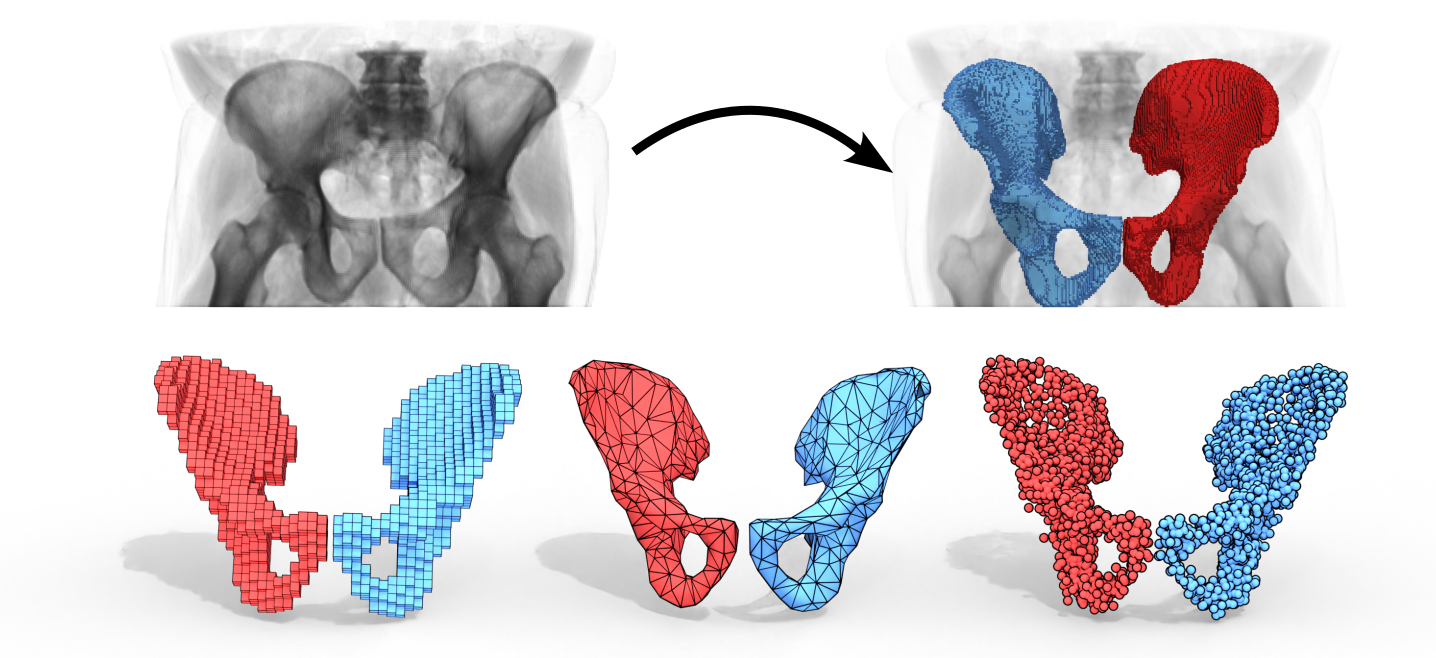

Each of these data structures have their own advantages and inconvenients:


*   Voxelized images are the typical output of 3D acquisition devices. Grid-based operations (like convolutions) can be efficiently implemented, allowing for fast local processing techniques. However, each voxel contains little information about the whole shape, making these data structure expensive to store.
*   Meshes rely on the triangulation of the encoded surface. They are way more efficient in terms of storage, as one triangle can span a large part of the surface. However, they are harder to manipulate; moreover, pathological triangulations can generate instabilities in their processing.
*   Point clouds are very generic, are simpler to model mathematically, and come with less encoding biases. However, they contain less structural information which creates ambiguity with respect to the encoded surface.

In practice, 3D surfaces are usually encoded as meshes, as it is the most appropriate structure to store surface information efficiently. In this part, we will learn to manipulate these data structures, understand their limitations, and see how to obtain uniform point clouds from arbitrary triangulations.



In [ ]:
"""
In this part, we will work with a 3D mesh representing a horse.
"""
mesh = trimesh.load('horse3d.ply')

A 3D mesh is encoded by two array wich includes geometric and connectivity information:

- `vertices`: An array of shape (N, 3) containing the 3D coordinates of the N vertices of the mesh. Each row represents the (x, y, z) position of a vertex.

- `faces`: An array of shape (Q, 3), of integer type, representing the Q triangular faces of the mesh. For the q-th triangle:

  - The vertex indices are `a = faces[q, 0]`, `b = faces[q, 1]`, and `c = faces[q, 1]`.

  - Their corresponding 3D coordinates are `vertices[a]`, `vertices[b]`, and `vertices[c]`.

In [ ]:
vertices_init = torch.tensor(mesh.vertices, dtype=torch.float32)
faces_init = torch.tensor(mesh.faces, dtype=torch.int64)

In [ ]:
print(f"Vertices shape: {vertices_init.shape}")
print(f"Faces shape: {faces_init.shape}")

In [ ]:
"""
Plot the 3D mesh.
"""
plot_mesh(vertices_init, faces_init)

In [ ]:
"""
Plot the vertices as a 3D point cloud.
"""
plot_vertices(vertices_init)

One advantage of the mesh structure is that it separates the geometric information and the connectivity information of the encoded shape. As a consequence, all classical geometric transformations like translations or rotations can be implemented by simply applying the transform to the mesh vertices.

**I.1. Apply a rotation of angle $\pi / 2$ around the x-axis to the mesh.**

In [ ]:
import math

In [ ]:
vertices = ...
faces = ...

"""The horse shape should now be straight."""
plot_mesh(vertices, faces)

In [ ]:
plot_vertices(vertices)

Using its face indices, we can also compute geometric features related to the triangles of the mesh.

**I.2.a. Get the position of each triangle vertices. Your result, `faces_vertices`, should be a tensor of shape (Q, 3, 3), where each element represents the 3D coordinates of a triangle's three vertices.**

In [ ]:
faces_vertices = ...

print(faces_vertices.shape)

**I.2.b. Get the barycenter of each face, i.e. the average position of its vertices. Your result, `faces_bar`, should be a tensor of shape (Q, 3) containing the 3D coordinates of each triangle's barycenter.**

In [ ]:
faces_bar = ...

plot_vertices(faces_bar)

**I.2.c. Compute the area of each triangle.  Your result, `faces_areas`, should be a tensor of shape (Q,).**

In [ ]:
faces_areas = ...

plt.hist(faces_areas, bins=100)
plt.title("Distribution of faces area")
plt.show()

plot_mesh(vertices, faces, color=faces_areas)

The previous question highlights one main drawback of mesh data structures: since the vertices are unevenly spread on the encoded surface, all triangles are not equally important and encode more or less information. Consequently, geometric processing pipelines must account for this heterogeneity in order to avoid biases towards areas with smaller triangles. This is particularly crucial to ensure consistent geometric algorithm, whose outputs are independent to the triangulation.

Besides face features, the mesh encoding also contains informations related to edges of the triangulations. Since the mesh data structure doesn't directly include edge information, these must be deduced from the `faces` array.

**I.3.a. Compute the indices of each edge in the mesh, i.e. all the pairs of indices contained in at least one triangle. Your result, `edges_indices`, should be an integer tensor of shape (P, 2).**

**You can use the `torch.unique` function to remove edge duplicates.**

In [ ]:
edges_indices = ...

print(edges_indices.shape)

**I.3.b. From `edges_indices`, compute the position of all edges extremities.  Your result, `edges_vertices`, should be a tensor of shape (P, 2, 3).**

In [ ]:
edges_vertices = ...

print(edges_vertices.shape)

plot_edges(edges_vertices) #If the result is correct, this instruction should plot the edges correctly

**I.3.c. Compute the average length of each edge.**

In [ ]:
edges_length = ...

print(edges_length.shape)

In [ ]:
plt.hist(edges_length, bins=100)
plt.title("Distribution of edge lengths in the mesh")
plt.show()

As with triangle areas, we see that the edge lengths are unevenly distributed, further evidencing the risk of bias inherent to mesh structures.

An other tricky aspect of mesh models is the fact that each vertex has a different number of neigboring faces/edges. This makes tensor-based computations unsuited to the processing of vertex neigborhoods, as these neighborood don't have a fixed shape.

**I.4.a. Using the function `torch.unique` with the parameter `return_counts=True`, compute the number of neighbooring triangles of each vertex.**

In [ ]:
face_degrees = ...

plt.hist(face_degrees, bins=20)
plt.title("Distribution of vertex degrees in the mesh")
plt.show()

**I.4.b. Similarly, compute the number of neighbooring edges of each vertex. What do you notice?**

In [ ]:
edge_degrees = ...

plt.hist(edge_degrees, bins=20)
plt.title("Distribution of vertex degrees in the mesh")
plt.show()

Due to the technicalities related to the manipulation of mesh structures, in the rest of the lab session, we will work with point set representations of meshes. As we will see, point clouds are easy to manipulate within the tensor framework; although less informative than meshes, they are well-suited to geometric tasks which focus on the global shape structure, like comparing shapes together, rather than on the local property of the surface. Therefore, we will now see how to robustly represent meshes as point clouds.

A straightforward way to obtain point sets from meshes is to isolate its vertices; however, it does not solve the problem of the heterogeneous spread of points:

In [ ]:
plot_vertices(vertices)

We will rather convert meshes to point sets by sampling uniformly on the mesh surface. To sample each point, we can rely on the following procedure:

  1. Choose a face of the mesh at random, with probabilities proportional to the face areas;
  2. Sample a point uniformly at random on a 2D triangle on which the sampling is easy to perform;
  3. Map the 2D point to the chosen face of the mesh by applying an affine transform from the 2D triangle to the 3D one.

This pipeline reduces the surface sampling problem to a sampling over 2D triangles, which is significantly easier. The first step avoid biases related to the faces heterogeneity, ensuring that the sampling is indeed uniform.


**I.5. Implement the sampling procedure.**

**In the first step, you can use the `torch.multinomial` function to sample an integer from a given discrete probability distribution.**

In [ ]:
N = 2048      # Number of points to sample

points = ...

In [ ]:
plot_vertices(points)

## c - [OPTIONAL] Spectral features on meshes

Although working with meshes is tricky and requires some care to avoid biases related to the triangulation choice, they also bear more information than point clouds about the local structure of the represented shape. This local information is generally encoded in the Laplacian, a linear operator that describes the local variations around each vertex. These are discrete adaptation of the continous Laplacian which corresponds to the second derivative operator:

$$ \Delta: f \in C^2(\mathbb{R}^2) \longmapsto \Delta f := \frac{\partial^2 f}{\partial x^2} + \frac{\partial^2 f}{\partial y^2} \in \mathbb{R}.$$

Intuitively, the value of $ \Delta f (x)$ quantifies the smoothness of $f$ at $x$, making it a natural object to study when focusing on the regularity of a geometric object. On discrete objects, several definitions exist which corresponds to different ways to approximate the continuous Laplacian $\Delta$. The simplest example, the *graph laplacian*, relies on the graph structure of the mesh. It attributes a value $\Delta f(x_i)$ to each vertex $x_i$ of a graph based on its cumulated difference with his adjacency vertices:

$$ \Delta f(x_i) = \sum_{x_j \sim x_i} ( f(x_i) - f(x_j) ),$$

where $u \sim v$ if $u$ and $v$ belong to a same edge. As a linear operator, the graph Laplacian can also be represented as a matrix $L \in \mathbb{R}^{N \times N}$ such that:

$$ \Delta f(x_i) = L_{ij} f(x_j), \quad \text{ where } L_{ij} = \begin{cases} -1 & \text{if }\; i \sim j, \\{\rm deg}(v_i) & \text{if }\; i = j, \\ 0 & \text{otherwise}. \end{cases} $$

Since a mesh comes with a graph structure provided by the triangulation edges, its graph Laplacian is well-defined and computable from its face indices.

**I.6. Compute the graph Laplacian matrix `L` of the mesh.**

In [ ]:
L = ...

In [ ]:
"""
Illustration of one column of the graph laplacian.
"""
idx = 144
vmax = L[:,idx].abs().max()
plot_mesh(vertices, faces, L[:,idx], clim=(-vmax, vmax), cmap='bwr')

Eigenfunctions of the Laplacian play a crucial role in the geometry of smooth surfaces. They are the solutions of differential equations of the form:

$$ \Delta f = \lambda f, \quad \lambda \in \mathbb{R}.$$

Analogously, on discrete objects, the eigenvectors of $L$ are central to many geometric processing algorithms. They allow to perform Fourier analysis on non-linear objects, as the eigenvectors of $L$ play the same role as Fourier basis on vector space. These eigenvectors also form a basis of $\mathbb{R}^N$ ordered by smoothness degree, the corresponding eigenvalues quantifying the smoothness of each vector. Finally, these eigenvectors can be used as a barcode of the shape which encodes the local structure of $X$.

In [ ]:
eigvals, eigvects = torch.linalg.eigh(L)

In [ ]:
"""
Visualization of the graph Laplacian eigenvectors, by increasing eigenvalue.
"""
for idx in range(10):
  print(f"===== Eigenvector {idx}: \t lambda = {eigvals[idx]} =====")
  vmax = eigvects[:,idx].abs().max()
  plot_mesh(vertices, faces, eigvects[:,idx], clim=(-vmax, vmax), cmap='bwr')

While simple, the graph Laplacian also discards geometric information related to the spacing of each vertex. In particular, it is very sensitive to the triangulation structure, and is therefore sensitive to the biases mentioned in the previous section. The *cotangent Laplacian* corrects this limitation by weighting each local difference as follows:

$$ \Delta f(x_i) = \frac{1}{2 A_i} \sum_{x_j \sim x_i} ({\rm cot}(\alpha_{ij}) + {\rm cot}(\beta_{ij})) ( f(x_i) - f(x_j) ).$$

Here, $\alpha_{ij} = {\rm angle}[(x_i,x_k), (x_k,x_j)]$ and $\beta_{ij} = {\rm angle}[(x_i,x_l), (x_l,x_j)]$, where $x_k$ and $x_l$ are the two only vertices such that $(x_i, x_j, x_k)$ and  $(x_i, x_j, x_l)$ are triangles of the mesh (indeed, in a triangulation, an edge belongs to exactly two triangles).
$A_i$ is the vertex area of $x_i$:

$$ A_{i} = \frac{1}{3} \sum_{T \text{ s.t. } x_i \subset T} {\rm area}(T). $$

Therefore, the corresponding Laplacian matrix reads:

$$ L_{ij} = \frac{C_{ij}}{A_{i}} \quad \text{ where } \quad  C_{ij} = \begin{cases} \frac{1}{2} ({\rm cot}(\alpha_{ij}) + {\rm cot}(\beta_{ij}) & \text{if }\; i \sim j, \\ - \sum_{k \neq i}{C_{ik}} & \text{if }\; i = j, \\ 0 & \text{otherwise}. \end{cases} $$

**I.7.a. Compute the cotangent matrix `C`.**

In [ ]:
def cotan(u, v):
  """
  Compute cotan(alpha), where alpha is the angle made by the vectors u and v.

  u, v: torch.Tensor(float) of size (N, 3)
  """
  return (u * v).sum(dim=1) / torch.cross(u, v, dim=1).norm(dim=1)

In [ ]:
C = ...

**I.7.b. Compute the vertex area vector `A`.**

**You can use the function `scatter_add_` from pytorch in order to implement this procedure efficiently.**

In [ ]:
A = ...

**I.7.c. Compute the cotangent Laplacian matrix `L`.**

In [ ]:
L = ...

In [ ]:
"""
Illustration of one column of the cotangent laplacian.
"""
idx = 144
vmax = L[:,idx].abs().max()
plot_mesh(vertices, faces, L[:,idx], clim=(-vmax, vmax), cmap='bwr')

Once again, we can compute the eigenvectors of the Laplacian. We observe some differences with the graph Laplacian:

In [ ]:
eigvals, eigvects = torch.linalg.eig(L)
eigvals, eigvects = eigvals.to(torch.float32), eigvects.to(torch.float32)

"""
Reorder the eigenvalues and eigenvectors by increasing magnitude.
"""
idx = torch.argsort(eigvals.abs())
eigvals, eigvects = eigvals[idx], eigvects[:,idx]

In [ ]:
"""
Visualization of the graph Laplacian eigenvectors, by increasing eigenvalue.
"""
for idx in range(10):
  print(f"===== Eigenvector {idx}: \t lambda = {eigvals[idx]} =====")
  vmax = eigvects[:,idx].abs().max()
  plot_mesh(vertices, faces, eigvects[:,idx], clim=(-vmax, vmax), cmap='bwr')

Visually, these eigenvectors vary more smoothly than the graph Laplacian ones. Variations are less important in areas with large vertex densities, correcting the geometric biases of the graph Laplacian.  

# II - Point Cloud Matching: from Nearest Neighbors to Optimal Transport

Since geometric shapes are spread across the space and cannot be naturally represented as vectors, comparing, combining and transfering information between geometric objects is not straightforward. These tasks being fundamental operations of data science, this represents a main challenge for geometric data analysis. To tackle these limitations, several strategies are available:

*   Describe the geometric objects as vectors of features;
*   Represent shapes as histograms (i.e. grid of voxels);
*   Compute correspondences between shapes that allows to quantify their differences and to compare their geometry locally.

The two first approaches are the simplest, but they come at the loss of information and are not adapted to precise comparison of geometric data. Therefore, we will rather focus on the latter.

There are two principal categories of methods that seek for correspondences between shapes: **matching**, that estimate pointwise pairing between two shapes, and **registration**, which deforms the ambient space to map one shape onto the other. This part is dedicated to the first approach; the second one will be treated in the next lab session.


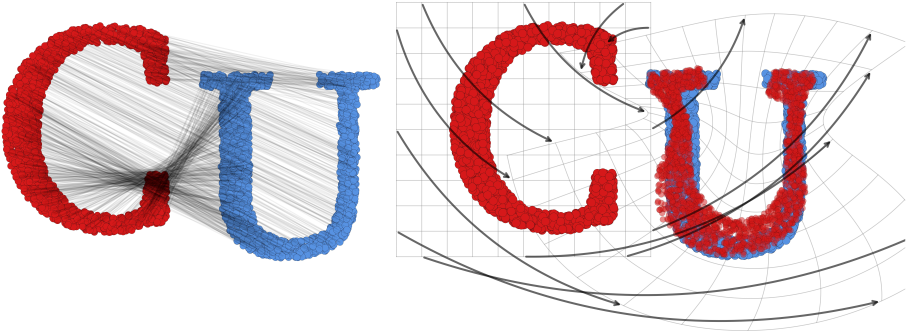

As detailed in the previous part, point clouds are easier to handle and more general than meshes: therefore, in the remaining of this notebook, we will mainly work with point clouds.
Given a two point sets (a source $x$ and a target $y$), our objective is to attribute a target point to each source point such that the pairing faithfully identifies the common geometric features of the inputs.

In [ ]:
"""
To simplify the results visualization, we will work with simple 2D point clouds representing digits.
"""
x = load_image_as_pointcloud('mnist_five_1.pt', N=2000)
y = load_image_as_pointcloud('mnist_five_2.pt', N=2000)

plot_pointcloud(x)
plot_pointcloud(y)

## a - Nearest neighbors and its regularized version

The simplest way to match two point clouds together is by computing the nearest neighbor (NN) of each source point. Denoting the source points by $x=(x_0, \dots, x_{N-1})$ and the target points by $y=(y_0, \dots, y_{M-1})$, and given a cost function $c: \mathbb{R}^3 \times \mathbb{R}^3 \mapsto \mathbb{R}$, the corresponding NN matching is a vector of indices ${\rm NN} \in [0, M-1]^N$ that satisfies:

$$ \text{For all } 0 \leq i < N, \quad {\rm NN}_i = \arg\min_j c(x_i, y_j), $$


The cost function $c$ encodes the length of each matching $x_i \leftrightarrow y_j$; here, we will use the $p$-powered euclidean distance:

$$ c(x, y) = \Vert x - y \Vert^p \quad \text{with } p > 0.$$

**II.1.a. Fill the `cost_matrix` function that computes the $p$-powered euclidean distance matrix between points of $x$ and $y$; that is, the matrix $C \in \mathbb{R}^{N \times M}$ such that $C_{ij} = c(x_i, y_j)$ for all $i,j$.**

In [ ]:
def cost_matrix(x, y, p=1):
  return ...

**II.1.b. Using `torch.argmin`, fill the `nearest_neighbors` function that computes the NN matching between $x$ and $y$ for the $p$-powered euclidean distance.**

In [ ]:
def nearest_neighbors(x, y, p=1):
  return ...

matching = nearest_neighbors(x,y, p=1)

The following plot represents the resulting matching:

In [ ]:
plot_matching(x, y, matching=matching)

An other way to visualize the matching is by transfering a predefined color code from the target to the source using the computed matching. Since they are mainly used to transfer local features between shapes, we expect "good" matchings to transfer smoothly and meaningfully on the source.

In [ ]:
plot_transfer(x, y, matching=matching)

These plots show that NN matchings are not satisfying: many points of the source are matched to the same target.
We also observe that transfered colors create lumps, evidencing the lack of smoothness of the resulting matching. In general, NN matchings are only relevant when the inputs almost overlaps; otherwise, the computed correspondences are not meaningful.

To alleviate this issue, we can replace the NN matching by a soft counterpart: rather than sending each source to its closest point, soft-NN matches each source point to a multitude of targets, the matching being encoded by a weight matrix $\pi \in [0, 1]^{N \times M}$ defined as:

$$\text{For all } i,j, \quad \pi_{ij} = \frac{\exp(-c(x_i,y_j) / \varepsilon ) }{ \sum_k \exp(-c(x_i,y_k) / \varepsilon ) }. $$

Sotf-NN can be interpreted as a non-deterministic matching: a probability distribution $\pi_{i\bullet}$ is assigned to each $x_i$ which represents the probability that $x_i$ is matched to each $y_j$, or the proportion of $x_i$ that is sent to $y_j$. Therefore, $\pi$ is a smoothed version of the NN matching - the parameter $\varepsilon > 0$ controlling the matching smoothness.


**II.2.a. Implement the `soft_nearest_neighbors` function that outputs the soft-NN matching $\pi$ between $x$ and $y$ for the $p$-powered euclidean distance.**

In [ ]:
def soft_nearest_neighbors(x, y, eps=1, p=1):
  return ...

pi = soft_nearest_neighbors(x, y, eps=5e-2, p=1)

Using soft-NN, the resulting matching becomes more diffuse and the color transfer is smoother:

In [ ]:
plot_matching(x, y, pi)
plot_transfer(x, y, pi)

However, the previous implementation is unstable for small $\varepsilon$: the exponential terms may explode, leading to `nan` in the output:

In [ ]:
"""
We compute soft-NN for an extremely small value of eps.
"""
pi = soft_nearest_neighbors(x, y, eps=1e-7, p=1)

"""
Each sum_k pi_{ik} should be equal to 1, but it contains nans:
"""
print(pi.sum(dim=1))

To ensure the stability of soft-NN, we can perform the computations in the log-domain, i.e. compute the matrix $\rho_{ij} = \log(\pi_{ij})$ instead of $\pi_{ij}$ and only return $\exp \rho_{ij}$ at the last moment. This tricks avoids the blow-up of the matrix coefficients, allowing to compute soft-NN for arbitrarily small values of $\varepsilon$.

**II.2.b. Implement the `soft_nearest_neighbors_log` function that computes the soft-NN matching in the log-domain. Use the function `torch.logsumexp` to compute the log-value of the denominator ($\log \left(\sum_k \exp(-c(x_i,y_k) / \varepsilon )\right)$) in a stable way.**

In [ ]:
def soft_nearest_neighbors_log(x, y, eps=1, p=1):
  return ...

This new implementation does not output any `nan` and provides a correct matching:

In [ ]:
pi = soft_nearest_neighbors_log(x, y, eps=1e-7, p=1)
print(pi.sum(dim=1))

In [ ]:
plot_matching(x, y, pi)
plot_transfer(x, y, pi)

We observe that the output corresponds exactly the (hard) NN matching. This property can be proven mathematically:

**II.3. [OPTIONAL] Prove that when $\varepsilon \rightarrow 0$, $\pi \rightarrow \pi^{\rm NN}$, where:**

\begin{equation}
\pi^{\rm NN}_{ij} =
 \begin{cases}
  1 & \text{ if } j = {\rm NN}(i), \\
 0 & \text{otherwise}.
 \end{cases}
\end{equation}
**(We assume here that ${\rm NN}(i)$ is unique for all $i$).**

The parameter $\varepsilon$ controls the amount of smoothing in the output:

In [ ]:
for eps in [1e-3, 5e-3, 1e-2, 5e-2, 1e-1]:
  print(f"===== eps = {eps} =====")

  pi = soft_nearest_neighbors_log(x, y, eps=eps, p=1)

  plot_matching(x, y, pi)
  plot_transfer(x, y, pi)

The cost function $c$ also has a slight influence on the matching:

In [ ]:
eps = 0.1
for p in [0.25, 0.5, 1, 2, 4]:
  print(f"===== p = {p} =====")
  pi = soft_nearest_neighbors_log(x, y, eps / cost_matrix(x, y, p=p).max(), p=p) # We rescale the parameter eps based on p to keep the results comparable

  plot_matching(x, y, pi)
  plot_transfer(x, y, pi)

When $p$ is small, source points that are far from the target tends to get blurry matchings, while short-range pairings are very sharp. We observe the opposite when $p$ is large: large-range pairings are sharp while short-range matching are blurrier. This phenomenon is due to the shape of the cost function $c$ for these different values of $p$:

In [ ]:
for p in [0.25, 0.5, 1, 2, 4]:
  u = torch.linspace(-1.1, 1.1, 101)
  v = cost_matrix(u[:,None], torch.tensor([[0.]]), p=p)

  plt.plot(u, v, label=f"p = {p}")

plt.legend()
plt.show()

The smaller $p$ is, the spikier $c$ is around $0$ and the flatter it is at larger distance. The soft-NN matching is sharpier when local variations of $c$ are large, since the cost function is more discriminative in areas where it changes rapidly; this explains the behavior previously observed.

## b - Bijective matching with optimal transport

Soft-NN partially solve the issues encountered with nearest neigbors, but its results remain unsatisfying. Indeed, the source points that are too far from the target remain poorly matched. Moreover, in many cases, a hard mapping between the source and the target is actually required, and soft matchings do not provide the expected outcome.

Intuitively, when the inputs have a similar shape, we want "good" matchings to be bijective: that is, to spread source points to the whole target, not on a small set of target points.
Optimal transport (OT) provides a way to compute such matchings.
Given two sets of positive weights $(a_0,\dots,a_{N-1})$ and $(b_0,\dots,b_{M-1})$ such that $\sum_i a_i = \sum_j b_j = 1$, the corresponding optimal transport is the solution of the optimization problem:

$$ \min_{\pi \in \Pi(a, b)} \sum_{ij} c(x_i,y_j) \pi_{ij},$$

where $\Pi(a, b)$ denotes the set of *transport plans* between $a$ and $b$:

\begin{equation*}
\Pi(a, b) := \left\{ \pi \in \mathbb{R}_+^{N \times M} \quad \text{ s.t. } \quad \sum_i \pi_{ij} = a_i \quad \text{and} \quad \sum_j \pi_{ij} = b_j \quad \text{for all } i,j \right\}
\end{equation*}

These equalities are called marginal constraints.
OT then searches for transport plan that minimizes the average length between each matched pair $(x,y)$, the corresponding length being measured by the cost function $c$.

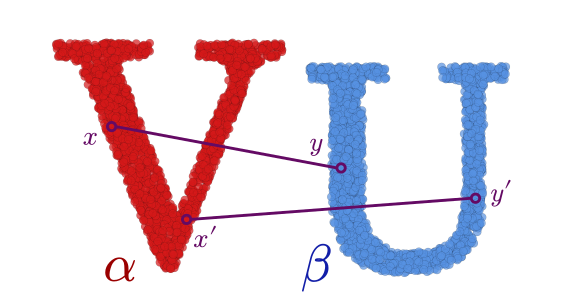

As with soft-NN, the final matching is given as a weight matrix $\pi$. However, when $N=M$ and with uniform weights ($a_i = b_j = 1/N$), the OT matching is actually a sharp, one-to-one mapping. Also, note that nearest neigbors can be seen as a relaxation of optimal transport. Indeed, the solution $\pi^{\rm NN}$ of the problem:

$$ \min_{\pi \in \mathbb{R}_+^{N \times M}} \sum_{ij} c(x_i,y_j) \pi_{ij} \quad \text{subject to} \quad \sum_i \pi_{ij} = \frac{1}{N} \quad \text{for all } i,$$

has the following structure:
\begin{equation}
\pi^{\rm NN}_{ij} =
 \begin{cases}
  \frac{1}{N} & \text{ if } j = {\rm NN}(i), \\
 0 & \text{otherwise}.
 \end{cases}
\end{equation}

Computing OT solutions is significantly harder than NN methods; therefore, we will rely on off-the-shelf implementations provided by the library [POT (Python Optimal Transport)](https://pythonot.github.io/).

In [ ]:
import ot

**II.4.a. Compute the uniform weight vectors `a`, `b` defining the OT constraints. Compute the matrix `C` of $\mathbb{R}^{N \times M}$ encoding the costs $[c(x_i,y_j)]_{ij}$, with $c$ corresponding to the Euclidean distance ($p=1$).**

In [ ]:
a = ...
b = ...

C = ...


"""
The ot.emd function directly solves the optimal transport problem associated to the given parameters.
"""
pi = ot.emd(a=a, b=b, M=C)

plot_matching(x, y, pi)
plot_transfer(x, y, pi)

The output is now a bijective matching. However, OT also creates long, undesirable pairings that make the resulting transfer really noisy. This problem can be partially corrected by choosing an appropriate cost function $c$, as we will see in the next question.

**II.4.b. Complete the following code that computes the OT associated to the $p$-powered Euclidean distance, for different values of $p$.**

In [ ]:
for p in [0.25, 0.5, 1, 2, 4, 8]:
  print(f"===== p = {p} =====")

  pi = ...

  plot_matching(x, y, pi)
  plot_transfer(x, y, pi)

As with soft-NN, the choice of $c$ changes the structure of the optimal matching at small and large scale. When $p$ is large, long-distance pairings are heavily penalized and optimal transport plans tend to remain local - avoiding the undesirable matchings observed earlier. On the contrary, small values of $p$ provide more accurate matchings at local scale but creates more long-range matchings as well.

Consequently, it may seem that large choices of $p$ are provide more satisfying solutions.
However, OT also tends to be more sensitive to outliers when $p$ is large.
To highlight this property, we will match two copies of the same point cloud $x$ after adding outliers at different extremities of the inputs.

In [ ]:
"""
Without outliers, the OT between two copies of x and match each point to itself.
Each pairing has a zero length, so we do not see any edge in the matching plot.
"""
C = cost_matrix(x, x, p=p)
a = torch.ones(x.shape[0]) / x.shape[0]

pi = ot.emd(a=a, b=a, M=C)

plot_matching(x, x, pi)

**II.5.a. Complete the following code by creating two point clouds `x1_noisy` and `x2_noisy`. Each of them contains the original point cloud $x$, plus `n_outliers` outliers sampled from a random gaussian $\mathcal{N}(\mu, \sigma=0.1)$:**

- **In `x1_noisy`, the gaussian is centered at $\mu = (2, 2)$.**
- **In `x2_noisy`, the gaussian is centered at $\mu = (-2, -2)$.**

**You can use `torch.concatenate` to append two tensors together.**

In [ ]:
for n_outliers in [1, 10, 100]:
  for p in [0.5, 1, 2, 4]:
    print(f"===== Nb of outliers = {n_outliers}, p = {p} =====")

    x1_noisy = ...
    x2_noisy = ...

    C = cost_matrix(x1_noisy, x2_noisy, p=p)

    a = torch.ones(x1_noisy.shape[0]) / x1_noisy.shape[0]
    b = torch.ones(x2_noisy.shape[0]) / x2_noisy.shape[0]

    pi = ot.emd(a=a, b=b, M=C)

    plot_matching(x1_noisy, x2_noisy, pi)
    plot_transfer(x1_noisy, x2_noisy, pi)

We notably notice that when $p\leq1$, the outliers are matched together and the rest of points are matched correctly. This is a consequence of the following fact, left as an exercise:

**II.5.b. [Optional] Prove the following claim:**
**When the cost is $c(x,y)=\Vert x - y \Vert^p$ with $p \leq 1$, then for each $(i,j)$ such that $x_i = y_j$, there is an optimal plan that satisfies $\pi_{ij} = \min (a_i, b_j)$.**

_Hint: use the triangular inequality and the fact that $(a + b)^p \leq a^p + b^p$ for all $a, b \in \mathbb{R}^+$ when $p \leq 1$._

## c - Variants of optimal transport

**Entropic Regularization.** Similarly to the NN case, optimal transport admits a "soft" version that locally smoothen the matching. This variant, called entropic optimal transport (EOT), corresponds to the following optimization problem:

$$ \min_{\pi \in \Pi(a, b)} \sum_{ij} c(x_i,y_j) \pi_{ij} + \varepsilon \text{KL}(\pi \Vert a \otimes b),$$

where $\text{KL}$ denotes the KL-divergence:

$$ \text{KL}(\pi \Vert a \otimes b) := \sum_{ij} \log \left(\frac{\pi_{ij}}{a_i b_j} \right) \pi_{ij}.$$

As we can see, the regularization parameter $\varepsilon$ control how much the transport plan is diffused:

In [ ]:
"""
For the next steps, we will use a smaller point clouds to fasten computations.
"""
x = load_image_as_pointcloud('mnist_five_1.pt', N=500)
y = load_image_as_pointcloud('mnist_five_2.pt', N=500)

In [ ]:
a = torch.ones(x.shape[0]) / x.shape[0]
b = torch.ones(y.shape[0]) / y.shape[0]
C = cost_matrix(x, y, p=1)

for reg in [1e-2, 5e-2]:
  print(f"===== Reg = {reg} =====")

  # The ot.sinkhorn function is designed for numpy arrays, so we convert tensors to numpy before computing the solution
  pi = ot.sinkhorn(a=a.numpy(), b=b.numpy(), M=C.numpy(), reg=reg, stopThr=1e-5, method='sinkhorn_stabilized')
  plot_matching(x, y, pi)
  plot_transfer(x, y, pi)

This regularized version has several advantages compared to classical optimal transport.
First, the resulting plan is smoother than with OT, and the EOT objective is differentiable with respect to the input points; we will explore this aspect more in detail in the next lab session. Second, since KL is strictly convex, EOT admits a unique solution, avoiding ambiguities that can arise when using standard OT.
Lastly, thanks to convex duality, EOT admits an alternative form that can be solved using an iterative method known as the *Sinkhorn algorithm*.
Indeed, it can be shown that EOT is equivalent to the dual maximization problem:

\begin{equation*}
  \max_{f \in \mathbb{R}^N}\; \max_{g \in \mathbb{R}^M} \quad \sum_{i} a_i f_i + \sum_{j} b_j g_j - \varepsilon \sum_{ij} a_i b_j \left[ \exp \left(\frac{f_i + g_j - c(x_i,y_j)}{\varepsilon}\right) - 1 \right].
\end{equation*}

The optimal EOT plan can then be recovered from the optimal $f$ and $g$ through the following calculation:

\begin{equation*}
\pi_{ij} = a_i b_j \exp \left( \frac{f_i + g_j - c(x_i,y_j)}{\varepsilon} \right).
\end{equation*}

The Sinkhorn algorithm simply consists in optimizing $f$ and $g$ alternately, keeping the other variable constant.
Starting from $f = 0$ and $g = 0$, it iterates the following updates:
\begin{equation*}
\begin{split}
f_i \gets & - \varepsilon \log \left(\sum_j \exp \left(\frac{g_j - c(x_i,y_j)}{\varepsilon} + \log b_j \right) \right), \\
g_j \gets & - \varepsilon \log \left(\sum_i \exp \left(\frac{f_i - c(x_i,y_j)}{\varepsilon} + \log a_i \right) \right).
\end{split}
\end{equation*}

**II.6.a. [Optional] Prove that, when $g$ is fixed, the Sinkhorn update on $f$ maximizes the dual problem introduced above. Similarly, prove that the Sinkhorn update on $g$ maximizes the dual formula with $f$ fixed.**

For non-optimal values of $f$ and $g$, the matrix $\pi_{ij} = a_i b_j \exp \left( \frac{f_i + g_j - c(x_i,y_j)}{\varepsilon} \right)$ is not a true transport plan, because it does not satisfy the constraints of $\Pi(a, b)$.
However, its marginals $\pi^X_i = \sum_j \pi_{ij}$ and $\pi^Y_j = \sum_i \pi_{ij}$ get increasly close to the target values $a_i$ and $b_j$ along the Sinkhorn iterations. Therefore, the discrepancy between $\pi^X$ (resp. $\pi^Y$) and $a$ (resp. $b$) can be used to quantify the convergence of Sinkhorn.

**II.6.b. Complete the following function that implements the Sinkhorn algorithm. Use `torch.logsumexp` to implement the updates in a stable way.**

In [ ]:
def sinkhorn(a, b, M, reg=0.1, numItermax=10000, stopThr=1e-5):
  """
  M is the cost matrix: M_ij = c(x_i, y_j);
  reg is the regularization parameter epsilon.
  """

  # Initialize f and g as vectors of zeros
  f = torch.zeros(a.shape[0])
  g = torch.zeros(b.shape[0])

  for it in range(numItermax):
      # Update f and g
      g = ...
      f = ...

      # Compute the current plan
      pi = ...

      # Compute the marginals of pi
      pi_x = ...
      pi_y = ...

      # We use the marginal constraint violations as a stopping criterion for the Sinkhorn algorithm
      if (pi_x - a).abs().sum() < stopThr and (pi_y - b).abs().sum() < stopThr:
        break

  print(f"Nb of iterations: {it}")

  return pi

In [ ]:
a = torch.ones(x.shape[0]) / x.shape[0]
b = torch.ones(y.shape[0]) / y.shape[0]
C = cost_matrix(x, y, p=1)

pi = sinkhorn(a=a, b=b, M=C, numItermax=10000, reg=2e-2, stopThr=1e-3)

The result should coincide with the matching obtained using the POT function:

In [ ]:
plot_matching(x, y, pi)
plot_transfer(x, y, pi)

**Unbalanced optimal transport.** In Unbalanced optimal transport (UOT), the marginal constraints of the EOT problem are relaxed and are replaced by a penalization of the constraint violations:

\begin{equation*}
\min_{\pi \in \mathbb{R}_+^{N \times M}} \sum_{ij} c(x_i,y_j) \pi_{ij} + \varepsilon \text{KL}(\pi \Vert a \otimes b) + \delta \text{KL}(\pi_X \Vert a) + \delta \text{KL}(\pi_Y \Vert b).
\end{equation*}

where $\pi_X$ and $\pi_Y$ are the marginals (in practice, the KL-divergence expressions have to be corrected because $\pi$ do not sum to $1$ anymore).
The parameter $\delta$ controls the relaxation of the marginals; when $\delta \rightarrow + \infty$, we recover classical EOT. This unbalanced OT variant better handles outliers in the input point clouds, since points that are too far from the target are ignored and remain unmatched in the optimal plan. This technique also corrects artifacts created by long-range matchings, providing more satisfying matchings when the inputs do not coincide exactly.


In [ ]:
a = torch.ones(x.shape[0]) / x.shape[0]
b = torch.ones(y.shape[0]) / y.shape[0]
C = cost_matrix(x, y, p=1)

for reg_m in [10, 1, 5e-1, 1e-1, 1e-2]:
    print(f"===== Reg_m = {reg_m} =====")

    pi = ot.sinkhorn_unbalanced(a=a, b=b, M=C, reg=2e-2, reg_m=reg_m, stopThr = 1e-5)

    print(f"Total mass of pi: {pi.sum()}") # In balanced OT, the sum of pi is equal to 1
    plot_matching(x, y, pi)
    plot_transfer(x, y, pi)


The previous experiment shows that, when $\delta$ is small, only the smallest pairings remain, and the sum of the coefficients of $\pi$ becomes close to $0$. The resulting color transfer is smoother, as only relevant matchings remain in the output.

Numerical resolution of UOT relies on the same approach as EOT. It also involves alternate updates of $f$ and $g$, the iterations being slightly modified:
\begin{equation*}
\begin{split}
f_i \gets & - \kappa \varepsilon \log \left(\sum_j \exp \left(\frac{g_j - c(x_i,y_j)}{\varepsilon} + \log b_j \right) \right), \\
g_j \gets & - \kappa \varepsilon \log \left(\sum_i \exp \left(\frac{f_i - c(x_i,y_j)}{\varepsilon} + \log a_i \right) \right),
\end{split}
\end{equation*}

with $\kappa = \delta / (\delta + \varepsilon)$.
As with EOT, the resulting matching is obtained through the following equation:

\begin{equation*}
\pi_{ij} = a_i b_j \exp \left( \frac{f_i + g_j - c(x_i,y_j)}{\varepsilon} \right).
\end{equation*}

**II.7. Complete the following function that implements the Unbalanced Sinkhorn algorithm using the previous updates.**

In [ ]:
def unbalanced_sinkhorn(a, b, M, reg=0.1, reg_m=100, numItermax=10000, stopThr=1e-5):
  """
  M is the cost matrix: M_ij = c(x_i, y_j);
  reg is the regularization parameter epsilon, and reg_m corresponds to delta.
  """

  f = torch.zeros(a.shape[0])
  g = torch.zeros(b.shape[0])

  for it in range(numItermax):
      f_old = f.clone()
      g_old = g.clone()

      g = ...
      f = ...

      # Since marginal constraints are not satisfied at optimality, using these as stopping criterion does not make sense.
      # Instead, we stop the iterations when the variations of f and g become smaller than the given threshold.
      if (f - f_old).abs().sum() < stopThr and (g - g_old).abs().sum() < stopThr:
        break

  print(f"Nb of iterations: {it}")

  pi = ...

  return pi

In [ ]:
a = torch.ones(x.shape[0]) / x.shape[0]
b = torch.ones(y.shape[0]) / y.shape[0]
C = cost_matrix(x, y, p=1)

pi = unbalanced_sinkhorn(a=a, b=b, M=C, numItermax=1000, reg=2e-2, reg_m=1e-1, stopThr=1e-5)

print(f"Total mass of pi: {pi.sum()}")

We should obtain the same result as with POT:

In [ ]:
plot_matching(x, y, pi)
plot_transfer(x, y, pi)

# III - Towards more Geometric-Accurate Matching methods

## a - Isometry-invariant matching with Gromov-Wasserstein

The NN and OT methods are simple, but they are only suited to inputs that are very similar to each other, as undesirable pairings may appear when the matched point clouds differ too much. An other drawback of these methods is their sensitivity to transformations of the ambient spaces. Indeed, although rotations and translations do not change the intrinsic shape of the inputs, these operations can significantly alter the corresponding matchings, which is unsuited to geometric-aware correspondences. The following experiment will highlight this important drawback.

In [ ]:
"""
For the next steps, we will use a smaller point clouds to fasten computations.
"""
x = load_image_as_pointcloud('mnist_five_1.pt', N=500)
y = load_image_as_pointcloud('mnist_five_2.pt', N=500)

plot_pointcloud(x)
plot_pointcloud(y)

**III.1. Implement the following functions. The first one should apply a rotation of angle `theta` to the 2D input point cloud. The second one should apply a translation of length `magnitude` towards the x-axis.**

In [ ]:
def rotation(points, theta):
  return ...

In [ ]:
def translation(points, magnitude):
  return ...

We observe that, after rotation of the inputs, the OT solution changes and creates undesirable matchings:

In [ ]:
a = torch.ones(x.shape[0]) / x.shape[0]
b = torch.ones(y.shape[0]) / y.shape[0]

for theta in [0, np.pi/4, np.pi/2, 3*np.pi/4, np.pi]:
  print(f"===== Theta = {theta}")

  y_rotated = rotation(y, theta=theta)
  C = cost_matrix(x, y_rotated, p=1)

  pi = ot.emd(a=a, b=b, M=C)
  plot_transfer(x, y_rotated, pi)

Similarly, translations perturbate the OT matching, yielding noisy correspondences:

In [ ]:
for magnitude in [0, 0.1, 0.5, 1, 10, 100]:
  print(f"===== Magnitude = {magnitude}")

  y_translated = translation(y, magnitude=magnitude)
  C = cost_matrix(x, y_translated, p=1)

  pi = ot.emd(a=a, b=b, M=C)
  plot_transfer(x, y_translated, pi)

Aiming to solve this limitation, the Gromov-Wasserstein (GW) problem is an alternative to OT that minimizes the distorsion induced by the transport rather than the displacement cost itself:

\begin{equation*}
\min_{\pi \in \Pi(\alpha, \beta)} \sum_{ijkl} ( c_X(x_i, x_k) - c_Y(y_j,y_l))^2 \pi_{ij} \pi_{kl},
\end{equation*}

where $c_X$ (resp. $c_Y$) is a cost function that only acts on the points of $x$ (resp. $y$).
In the GW matching, if $x$ is matched to $y$ and $x'$ is matched to $y'$, then the values of $c_X(x,x')$ and $c_Y(y,y')$ should be as similar as possible: consequently, GW searches for matchings that are as *isometric* as possible, i.e. that will preserve the pairwise lengths of the inputs - these lengths being measured by $c_X$ and $c_Y$.

In our experiments, we will take $c_X = c_Y = c$ to be the Euclidean distance (with $p=1$); however, the choice of these functions is determinant to the structure of the final matching.

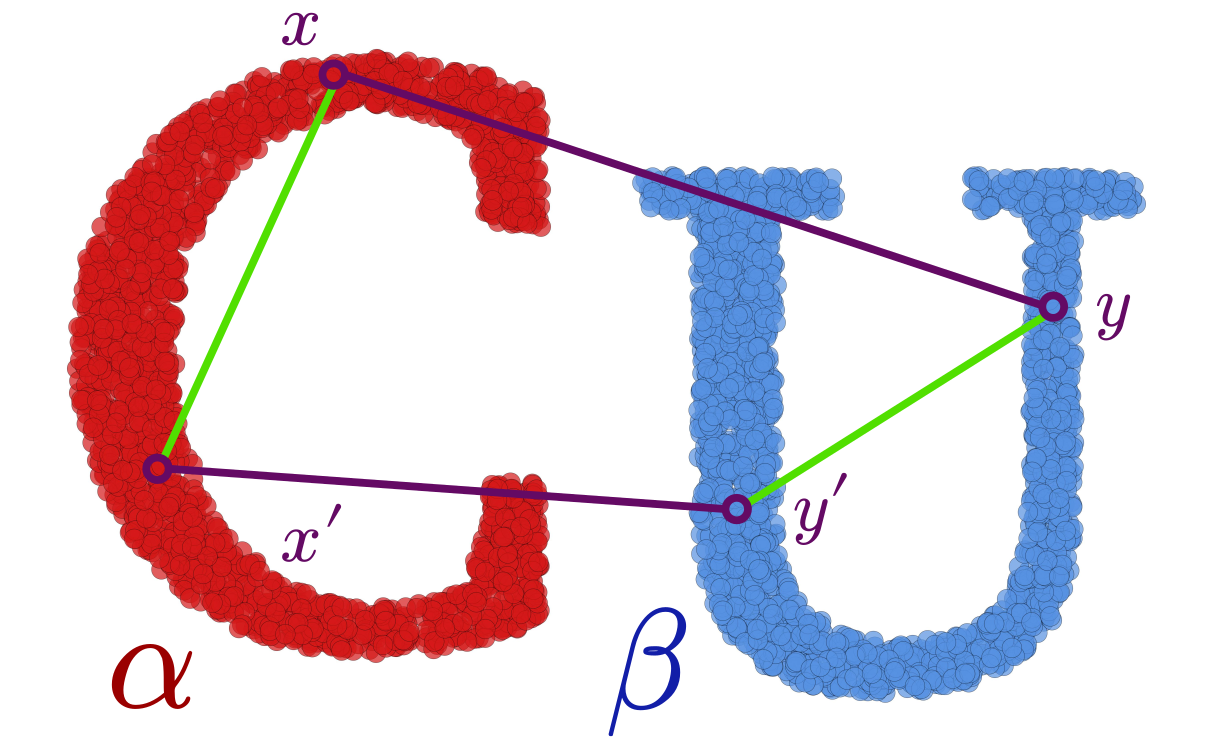


**III.2. Compute the self-distance matrices of $x$ and $y$; that is, the matrices $C^X \in \mathbb{R}^{N \times N}$ and $C^Y \in \mathbb{R}^{M \times M}$ such that $C^X_{ik} = c(x_i, x_k)$ for all $i,k$ and $C^Y_{jl} = c(y_j, y_l)$ for all $j,l$.**

In [ ]:
Cx = ...
Cy = ...

We now use POT to compute the GW matching:

In [ ]:
pi = ot.gromov_wasserstein(Cx, Cy)

plot_matching(x, y, pi)
plot_transfer(x, y, pi)

Besides its independence to isometries, GW also has the advantage to provide smoother matchings. Indeed, the optimization objective enforces a certain notion of smoothness, avoiding the matching discontinuities that we observed when using optimal transport.
However, GW is also harder to solve: this is a non-convex minimization problem whose global solutions are difficult to identify. Moreover, the spatial disposition of inputs usually contains prior information (e.g. left-right and top-bottom orientation) that is discarded by GW, which may lead to geometrically correct but unexpected matchings (such as above).

Since GW is hard to solve globally, in practice, solvers rely on local optimization which are sensitive to the initialization. To illustrate this behavior, we will initialize the solver with random transport plans and observe how the result depends on the initialization.

**III.3. Generate random permutation matrices between `x` and `y`. More specifically, since $N = M$, compute a random permutation $\sigma \in \mathfrak{S}_N$ (using `torch.randperm`) and compute the corresponding $N \times N$ matrix:**

$$ G^0_{ij} = \begin{cases} 1/N & \text{ if } i = \sigma(j) \\
0 & \text{otherwise}.
\end{cases}
$$

In [ ]:
for it in range(10):
  print(f"===== Initialization {it} =====")
  G0 = ...

  # We initialize the Gromov-Wasserstein solver with the transport plan G0:
  pi = ot.gromov_wasserstein(Cx, Cy, G0=G0)

  plot_matching(x, y, pi)
  plot_transfer(x, y, pi)

Consequently, the GW initialization greatly influences the nature of the output matching; this is a common property of all non-trivial matching algorithms.

We will now see how to solve the GW problem numerically. First, we remark that GW is equivalent to:

\begin{equation*}
\min_{\pi \in \Pi(a, b)} {\rm Cste} - 2 \sum_{ijkl} c_X(x_i, x_k) c_Y(y_j,y_l) \pi_{ij} \pi_{kl},
\end{equation*}

where the constant do not play any role in the optimization.

**III.4.a. [Optional] Prove the equivalence claimed above.**

_Hint: use the fact that $\sum_i \pi_{ij} = a_i$ and $\sum_j \pi_{ij} = b_j$ are constant for any $\pi \in \Pi(a,b)$._



The *Franke-Wolfe algorithm* (also named *conditional gradient method*) solves this equivalent problem by iterating the following updates:

\begin{equation*}
\begin{split}
  \tilde{c}(x_i, y_j) \gets & - 2 \sum_{kl} c_X(x_i, x_k) c_Y(y_j,y_l) \pi_{kl} \\
  \pi \gets & \min_{\pi \in \Pi(a, b)} \sum \tilde{c}(x_i, y_j) \pi_{ij},
\end{split}
\end{equation*}

where the second step correspond to an OT problem for the effective cost $\tilde{c}$.

**III.4.b. Complete the following function, that implements the Franke-Wolfe algorithm for Gromov-Wasserstein. You can use `ot.emd` to solve the intermediate OT problems. For stabilization, renormalize the effective cost matrix at each OT step by dividing it by its largest value.**


In [ ]:
def gromov_wasserstein(Cx, Cy, a, b, G0=None, numItermax=100):
  # Initialization of the transport plan.
  if G0 is None:
    pi = a[:,None] * b[None,:]
  else:
    pi = G0

  for it in range(numItermax):
    print(f"Iteration {it}/{numItermax}")
    C = ...
    pi = ...

  return pi

In [ ]:
Cx = cost_matrix(x, x, p=1)
Cy = cost_matrix(y, y, p=1)

a = torch.ones(x.shape[0]) / x.shape[0]
b = torch.ones(y.shape[0]) / y.shape[0]

We should obtain the same result as earlier:

In [ ]:
pi = gromov_wasserstein(Cx, Cy, a=a, b=b, numItermax=30)

plot_matching(x, y, pi)
plot_transfer(x, y, pi)

## b - [OPTIONAL] A short introduction to functional maps for mesh matching

As discussed in section I.b., meshes contain crucial information about the local shape structure which cannot be exploited when simply working with point clouds. We will now see how to exploit this information to compute more accurate matchings using a framework called *functional maps*. It relies on the two following ideas:

1.   To compute correspondences between shapes, we don't have to find pointwise pairings but we can match more global features such as smooth functions defined on these shapes,
2.   The Laplacian eigenvectors of two similar shapes have a similar appearance.

Given two shapes $X$ and $Y$, functional maps searches for a linear correspondence $T: L^2(Y) \to L^2(X)$ between the spaces of (squared-integrable) functions defined on Y and X. In the discrete case, functions of $X$ (resp. $Y$) are represented as vector of $\mathbb{R}^N$ (resp. $\mathbb{R}^M$) giving its value on each vertex $x_i$ (resp. $y_j$).
Therefore, the functional map $T$ is simply a matrix $C \in \mathbb{R}^{M \times N}$ transforming functions of $Y$ into functions of $X$.

Rather than working on the full spaces of functions, we restrict them to the space generated by the first $Kx$ and $Ky$ eigenvectors of the mesh Laplacians (where $K_x \ll N$ and $K_y \ll M$). By doing so, we reduce the size of $C$ to $\mathbb{R}^{K_x \times K_y}$, improving the computation speed, while forcing the matching to send smooth functions on smooth functions.

In [ ]:
mesh_x = trimesh.load('horse3d.ply')
mesh_y = trimesh.load('horse3d_2.ply')

vertices_x = torch.tensor(mesh_x.vertices, dtype=torch.float32)
faces_x = torch.tensor(mesh_x.faces, dtype=torch.int64)

vertices_y = torch.tensor(mesh_y.vertices, dtype=torch.float32)
faces_y = torch.tensor(mesh_y.faces, dtype=torch.int64)

First of all, we preprocess the input meshes in order to ease their visualization and to ensure that their scales are comparable.

**III.5. Center the two meshes, normalize them by average distance to the origin, and apply a rotation of angle $\pi / 2$ around the x-axis.**

In [ ]:
vertices_x = ...
vertices_y = ...

In [ ]:
plot_mesh(vertices_x, faces_x)
plot_mesh(vertices_y, faces_y)

We now compute the Laplacian eigendecomposition of both meshes. We denote by $\lambda^X_k$, $\lambda^Y_k$ the $k$⁻th eigenvalue and $\Phi^X_k$, $\Phi^Y_k$ the the $k$⁻th eigenvector of both Laplacians.

In [ ]:
"""
Number of eigenvectors of X and Y to compute.
"""
Kx, Ky = 50, 51

In [ ]:
"""
The library PP3D direclty provides implementations of the cotangent laplacian and the vertex areas.
"""
cotan_x = pp3d.cotan_laplacian(vertices_x.numpy(), faces_x.numpy()).astype(float)
cotan_y = pp3d.cotan_laplacian(vertices_y.numpy(), faces_y.numpy()).astype(float)

area_x = pp3d.vertex_areas(vertices_x.numpy(), faces_x.numpy()).astype(float)
area_y = pp3d.vertex_areas(vertices_y.numpy(), faces_y.numpy()).astype(float)

"""
Since the Laplacian is sparse, and because we are only interested in a subset of all eigenvectors, we use the scipy.sparse
eigendecomposition.
"""
eigvals_x, eigvects_x = scipy.sparse.linalg.eigsh(cotan_x, k=Kx, M=np.diag(area_x), sigma=-0.01)
eigvals_y, eigvects_y = scipy.sparse.linalg.eigsh(cotan_y, k=Ky, M=np.diag(area_y), sigma=-0.01)

In [ ]:
"""
Tensor of eigenvalues.
"""
lmbda_x = torch.tensor(eigvals_x, dtype=torch.float32)
lmbda_y = torch.tensor(eigvals_y, dtype=torch.float32)

"""
Tensor of eigenvectors.
"""
phi_x = torch.tensor(eigvects_x, dtype=torch.float32)
phi_y = torch.tensor(eigvects_y, dtype=torch.float32)

We can represent the first eigenvectors of both shapes. Up to a change of sign, we observe that these eigenvectors are indeed similar:

In [ ]:
for idx in range(10):
  print(f"===== Eigenvector {idx} =====")
  vmax = phi_x[:,idx].abs().max()
  plot_mesh(vertices_x, faces_x, phi_x[:,idx], clim=(-vmax, vmax), cmap='bwr')

  vmax = phi_y[:,idx].abs().max()
  plot_mesh(vertices_y, faces_y, phi_y[:,idx], clim=(-vmax, vmax), cmap='bwr')

To compute matchings using functional maps, we alternate between two steps: **functional map optimization** and **pointwise matching computation**.

Given a pointwise matching $m \in [0, M-1]^N$, the first step searches for the solution of the following equation:

$$ \min_{C \in \mathbb{R}^{Kx \times Ky}} \sum_{ik} [(\Phi^Y C)_{ik} - \Phi^X_{m(i) k}]^2 + \rho \sqrt{\sum_{kl} [ C_{kl} \lambda^Y_k - C_{kl} \lambda^X_l]^2}. $$
The first term forces $C$ to send $\Phi^X$ onto $\Phi^Y$ as accurately as possible; this is a typical linear regression objective.
The second one incites $C$ to send eigenvectors of $Y$ to eigenvectors of $X$ with similar eigenvalues, hence promoting functional correspondences that preserve the Laplacian structure. Informally, it forces $C$ to be as "diagonal" as possible, preserving the smoothness order of the Laplacian basis.

**III.6.a. Complete the following function that minimizes the previous quantity. You should compute `loss` that corresponds to the functional map objective.**

In [ ]:
"""
We use the autodifferentiation of Pytorch to optimize the functional map C without relying on complex optimization
procedures.
"""

def fm_optimization(matching, phi_x, phi_y, lmbda_x, lmbda_y, Kx, Ky, rho=1):
  C = torch.zeros(Ky, Kx, requires_grad=True)           #requires_grad = True activates the autodiff. on the variable C.
  optimizer = torch.optim.LBFGS([C])                    # Defines an optimizer object that will update C until it minimizes the desired function.

  def fm_energy():
    optimizer.zero_grad()                               # Reset the gradients stored in the optimizer

    loss = ...

    loss.backward()                                     # Computes the gradient of loss w.r.t. C (that will be used internally by the optimizer)
    return loss

  optimizer.step(fm_energy)                             # Optimize the function fm_energy w.r.t. C

  return C.detach()                                     # We don't need to compute the gradients of C anymore; C.detach()

The second step computes pairwise matching between shapes based on the  functional basis using nearest neighbors, as follows:

$$m(i) = \arg\min_j \Vert (\Phi^Y C)_j - \Phi^X_i \Vert.$$

**III.6.b. Complete the following function that implements the pairwise matching step.**

In [ ]:
def pairwise_matching(C, phi_x, phi_y):
  return ...

We are now ready to compute the functional maps matching. We start from a raw matching $m = {\rm NN}$ computed with nearest neighbors:

In [ ]:
nn_matching = nearest_neighbors(vertices_x, vertices_y, p=1)

"""
An other way to represent matchings between shapes is by transfering a texture, such as this
checkerboard, from one shape to the other:
"""
plot_mesh_transfer(vertices_x, faces_x, vertices_y, faces_y, matching=nn_matching)

We are now ready to compute the matching between our shapes:

In [ ]:
for it in range(5):
  print(f"===== Iteration {it} =====")
  C = fm_optimization(matching, phi_x, phi_y, lmbda_x, lmbda_y, Kx, Ky, rho=10)
  matching = pairwise_matching(C, phi_x, phi_y)

  """
  Representation of the functional map matrix C.
  """
  vmax = C.abs().max()
  plt.matshow(C.detach(),vmin=-vmax, vmax=vmax, cmap='bwr')
  plt.show()

  """
  Texture transfer obtained with the current matching.
  """
  plot_mesh_transfer(vertices_x, faces_x, vertices_y, faces_y, matching=matching)

We observe that the final matching is significantly more accurate than the original NN pairing and provides a smoother texture transfer. We also see that the functional map $C$ concentrates around the diagonal, which indicates that, as expected, the corresponding eigenvectors of both shapes are roughly matched together. This small example highlights how spectral information provided by mesh Laplacians can be exploited in problems involving the comparison of shapes.